# Thực nghiệm nhận diện khuôn mặt: MTCNN, FaceNet và Optical Flow

## 1. Giới thiệu

Hệ thống dùng OpenCV, MTCNN và FaceNet: phát hiện khuôn mặt từ khung hình webcam, căn chỉnh, trích xuất vector đặc trưng 128 chiều rồi so với khuôn mặt tham chiếu bằng độ tương đồng cosine.

**Quy tắc quyết định:** similarity ≥ 0.70 → `Matched`; ngược lại → `Unknown`.

**Quy trình:** Webcam/Ảnh → MTCNN → Căn chỉnh mặt → FaceNet (128D) → Cosine → Matched / Unknown

**Phần minh họa pipeline:** sử dụng ba ảnh tĩnh (một ảnh tham chiếu và hai ảnh kiểm thử):

1. Phát hiện mặt và điểm mốc (MTCNN)
2. Căn chỉnh mặt
3. Trích xuất đặc trưng (FaceNet)
4. So khớp bằng cosine
5. Đối chứng: có và không căn chỉnh

Danh tính thực tế của hai ảnh Test cần được xác nhận trước khi tính đúng/sai; không tự gán ground truth.
**Bố cục notebook:** (1) Giới thiệu; (2) Thiết lập; (3) Minh họa pipeline trên ba ảnh; (4) Đối chứng căn chỉnh; (5) Tổng hợp thí nghiệm ba ảnh; (6) Đánh giá xác minh trên 100 cặp; (7) Benchmark webcam; (8) Kết luận.

**Lưu ý:** Các số liệu và biểu đồ lưu sẵn là kết quả của lần chạy trước. Cần chạy lại toàn bộ notebook để xác nhận tính tái lập trên môi trường hiện tại.


## 2. Môi trường và dữ liệu

### 2.1. Thiết lập

Notebook dùng lại các module trong `src/`, không cài đặt lại thuật toán.

In [34]:
from pathlib import Path
import sys

# Nếu notebook được lưu ngoài project, điền đường dẫn thư mục project tại đây.
# Ví dụ: PROJECT_DIR = r"C:\Users\NAO\face_detection_segmentation"
PROJECT_DIR = ""

CURRENT_DIR = Path.cwd().resolve()

def is_project_root(folder):
    return (folder / "src" / "config.py").is_file() and (folder / "data").is_dir()

if PROJECT_DIR.strip():
    ROOT = Path(PROJECT_DIR).expanduser().resolve()
    if not is_project_root(ROOT):
        raise FileNotFoundError(f"PROJECT_DIR không trỏ đến thư mục project hợp lệ: {ROOT}")
else:
    # Tìm từ working directory và các thư mục cha.
    candidates = [CURRENT_DIR, *CURRENT_DIR.parents]
    ROOT = next((p for p in candidates if is_project_root(p)), None)
    if ROOT is None:
        # Trường hợp notebook được mở từ thư mục documents nằm cạnh project.
        sibling_candidates = [child for parent in candidates[:3]
                              for child in parent.iterdir() if child.is_dir()]
        ROOT = next((p for p in sibling_candidates if is_project_root(p)), None)
    if ROOT is None:
        raise FileNotFoundError(
            f"Không tìm thấy project từ working directory: {CURRENT_DIR}\n"
            "Hãy điền PROJECT_DIR ở đầu cell này bằng đường dẫn tuyệt đối đến thư mục chứa src/ và data/."
        )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Working directory:", CURRENT_DIR)
print("Project ROOT:", ROOT)
print("Reference path:", ROOT / "data/reference/image.jpg")

Working directory: C:\Users\NAO\Downloads\lab5_face_ID\document
Project ROOT: C:\Users\NAO\Downloads\lab5_face_ID
Reference path: C:\Users\NAO\Downloads\lab5_face_ID\data\reference\image.jpg


In [35]:
# Standard library
import sys
from pathlib import Path

# Third-party libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Project modules
from src.config import REFERENCE_PATH, SIMILARITY_THRESHOLD
from src.face_detector import FaceDetector
from src.face_alignment import align_face
from src.face_embedder import FaceEmbedder
from src.face_matcher import FaceMatcher
from src.visualizer import draw_results

### 2.2. Dữ liệu

| Tên | Tệp | Đặc điểm |
|---|---|---|
| Reference | `data/reference/image.jpg` | Ảnh tham chiếu, đầu nghiêng, nền tường |
| Test 1 | `data/evaluation/image1.jpg` | Nhìn thẳng, ánh sáng sân khấu, có logo và banner quảng cáo |
| Test 2 | `data/evaluation/image2.jpg` | Đeo kính, một tay chạm gọng kính, nền tối |

Ảnh được đọc bằng OpenCV (BGR), chỉ đổi sang RGB khi hiển thị bằng Matplotlib.

**Phân biệt đường dẫn:** phần minh họa này dùng `data/reference/image.jpg`, trong khi `main.py` dùng `data/reference/my_face.jpg` theo `src/config.py`. Hai ảnh có thể khác nhau; muốn đối chiếu trực tiếp cần dùng cùng một ảnh và chạy lại các cell liên quan.

In [36]:
IMAGE_PATHS = {
    "Reference": ROOT / "data/reference/image.jpg",
    "Test 1": ROOT / "data/evaluation/image1.jpg",
    "Test 2": ROOT / "data/evaluation/image2.jpg",
}

for name, path in IMAGE_PATHS.items():
    assert path.is_file(), f"Image not found: {path}"
    print(f"{name}: FOUND")

Reference: FOUND
Test 1: FOUND
Test 2: FOUND


In [37]:
# Nạp ảnh
images = {}

for name, path in IMAGE_PATHS.items():
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    images[name] = image

    print(f"{name}: {image.shape}")

Reference: (447, 447, 3)
Test 1: (640, 480, 3)
Test 2: (447, 447, 3)


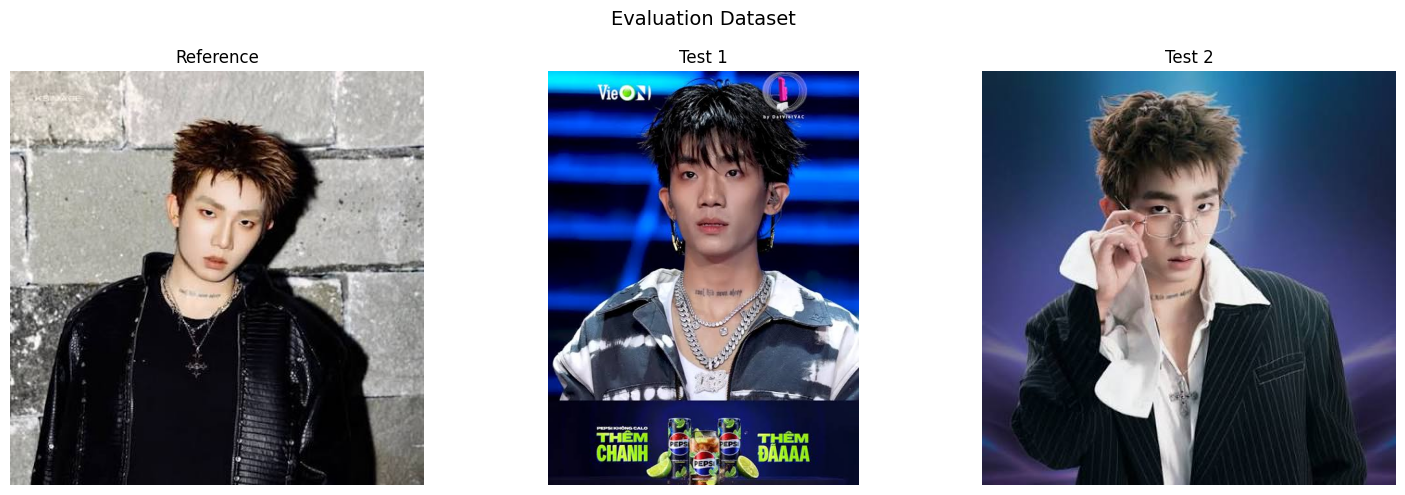

In [38]:
# Trực quan hóa ảnh đầu vào
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, image) in zip(axes, images.items()):
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(rgb_image)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle("Evaluation Dataset", fontsize=14)
plt.tight_layout()
plt.show()

**Nhận xét:** Cả 3 ảnh được nạp thành công. Hai ảnh kiểm thử khác ảnh tham chiếu về nền, ánh sáng và phụ kiện (kính), nên phép thử gần với điều kiện thực tế hơn so với ảnh chụp cùng bối cảnh.

## 3. Minh họa pipeline trên ba ảnh

### 3.1. Phát hiện khuôn mặt bằng MTCNN

#### Phương pháp

MTCNN trả về với mỗi khuôn mặt:

- **Hộp bao** `(x, y, w, h)`
- **Độ tin cậy** của phát hiện
- **5 điểm mốc:** mắt trái, mắt phải, mũi, hai khóe miệng

Các điểm mốc được dùng để căn chỉnh mặt ở Mục 3.2.

In [39]:
detector = FaceDetector()

detection_results = {}

for name, image in images.items():
    faces = detector.detect(image)
    detection_results[name] = faces

    print(f"\n{name}: {len(faces)} face(s) detected")

    for i, face in enumerate(faces):
        print(f"  Face {i + 1}")
        print(f"  Box: {face['box']}")
        print(f"  Confidence: {face['confidence']:.4f}")
        print(f"  Keypoints: {face['keypoints']}")


Reference: 1 face(s) detected
  Face 1
  Box: [187, 103, 86, 127]
  Confidence: 0.9893
  Keypoints: {'nose': [np.int64(231), np.int64(186)], 'mouth_right': [np.int64(236), np.int64(206)], 'right_eye': [np.int64(255), np.int64(164)], 'left_eye': [np.int64(216), np.int64(153)], 'mouth_left': [np.int64(209), np.int64(200)]}

Test 1: 1 face(s) detected
  Face 1
  Box: [183, 97, 142, 185]
  Confidence: 0.9998
  Keypoints: {'nose': [np.int64(252), np.int64(198)], 'mouth_right': [np.int64(278), np.int64(237)], 'right_eye': [np.int64(285), np.int64(157)], 'left_eye': [np.int64(219), np.int64(159)], 'mouth_left': [np.int64(228), np.int64(236)]}

Test 2: 1 face(s) detected
  Face 1
  Box: [157, 95, 97, 138]
  Confidence: 0.9999
  Keypoints: {'nose': [np.int64(220), np.int64(181)], 'mouth_right': [np.int64(228), np.int64(202)], 'right_eye': [np.int64(236), np.int64(147)], 'left_eye': [np.int64(192), np.int64(150)], 'mouth_left': [np.int64(200), np.int64(204)]}


#### Kết quả trực quan phát hiện khuôn mặt

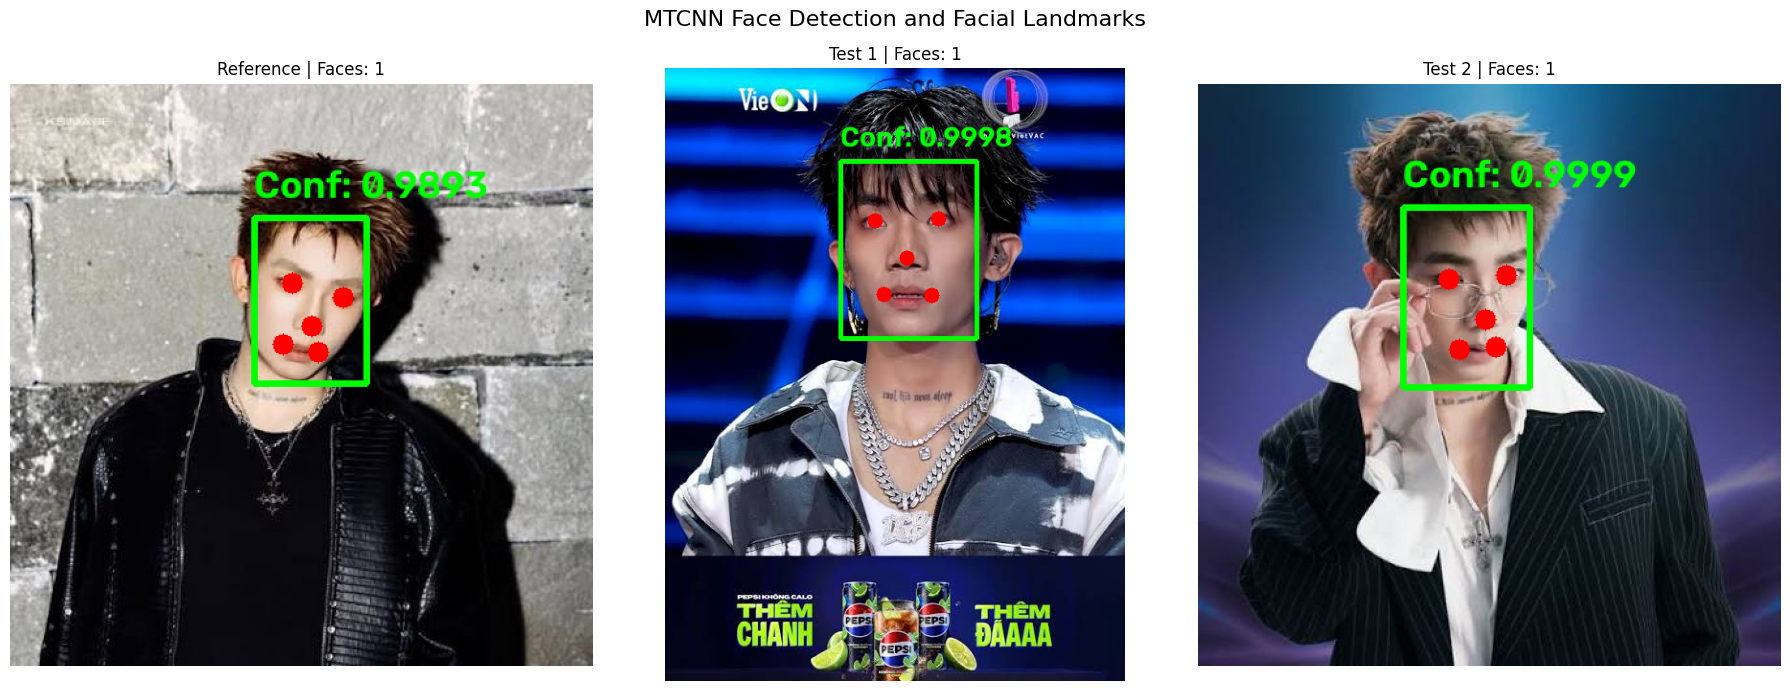

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, (name, image) in zip(axes, images.items()):
    annotated_image = image.copy()

    for face in detection_results[name]:
        x, y, w, h = map(int, face["box"])
        confidence = float(face["confidence"])

        # Bounding box
        cv2.rectangle(
            annotated_image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

        # Detection confidence
        cv2.putText(
            annotated_image,
            f"Conf: {confidence:.4f}",
            (x, max(y - 15, 30)),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            3
        )

        # Five facial landmarks
        for point in face["keypoints"].values():
            px, py = map(int, point)
            cv2.circle(annotated_image, (px, py), 8, (0, 0, 255), -1)

    display_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

    ax.imshow(display_rgb)
    ax.set_title(
        f"{name} | Faces: {len(detection_results[name])}"
    )
    ax.axis("off")

plt.suptitle("MTCNN Face Detection and Facial Landmarks", fontsize=16)
plt.tight_layout()
plt.show()

**Nhận xét kết quả phát hiện:**

MTCNN phát hiện đúng 1 khuôn mặt ở cả 3 ảnh. Độ tin cậy: Reference **0.9893**, Test 1 **0.9998**, Test 2 **0.9999**.

Logo, banner (Test 1) và kính, bàn tay (Test 2) không gây phát hiện nhầm hay làm mất điểm mốc. Reference có độ tin cậy thấp nhất, có thể do đầu nghiêng và khuôn mặt nhỏ hơn. Kết quả chỉ trên 3 ảnh nên chưa phản ánh độ chính xác tổng quát.

### 3.2. Căn chỉnh khuôn mặt

#### Phương pháp

Dùng hai điểm mốc mắt để xoay ảnh bù độ nghiêng đầu, rồi cắt vùng mặt làm đầu vào cho FaceNet:

1. Lấy toạ độ hai mắt.
2. Tính góc giữa hai mắt.
3. Xoay ảnh để hai mắt nằm ngang.
4. Cắt vùng mặt.

#### Kết quả

In [41]:
aligned_faces = {}
original_faces = {}

for name, image in images.items():
    faces = detection_results[name]

    if len(faces) == 0:
        print(f"{name}: No face detected")
        continue

    # Chọn khuôn mặt có confidence cao nhất
    face = max(faces, key=lambda f: f["confidence"])

    x, y, w, h = map(int, face["box"])

    # Giới hạn tọa độ trong kích thước ảnh
    height, width = image.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)

    original_crop = image[y1:y2, x1:x2].copy()

    # Gọi module alignment của project
    aligned_crop = align_face(image, face)

    if original_crop.size == 0 or aligned_crop is None or aligned_crop.size == 0:
        print(f"{name}: Invalid face crop")
        continue

    original_faces[name] = original_crop
    aligned_faces[name] = aligned_crop

    print(f"{name}")
    print(f"  Original shape: {original_crop.shape}")
    print(f"  Aligned shape:  {aligned_crop.shape}")

Reference
  Original shape: (127, 86, 3)
  Aligned shape:  (160, 160, 3)
Test 1
  Original shape: (185, 142, 3)
  Aligned shape:  (160, 160, 3)
Test 2
  Original shape: (138, 97, 3)
  Aligned shape:  (160, 160, 3)


#### Trực quan hóa ảnh trước và sau căn chỉnh

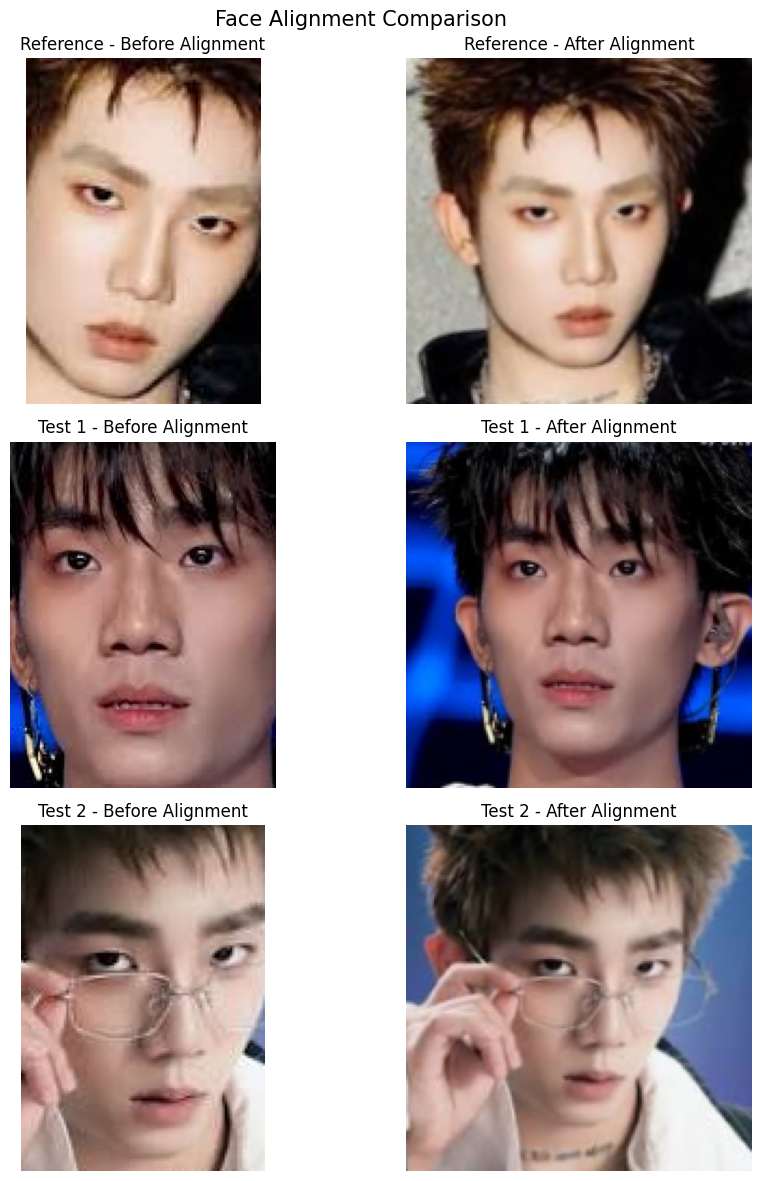

In [42]:
names = list(aligned_faces.keys())

fig, axes = plt.subplots(
    len(names), 2,
    figsize=(10, 4 * len(names)),
    squeeze=False
)

for i, name in enumerate(names):
    before = original_faces[name]
    after = aligned_faces[name]

    axes[i, 0].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{name} - Before Alignment")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"{name} - After Alignment")
    axes[i, 1].axis("off")

plt.suptitle("Face Alignment Comparison", fontsize=15)
plt.tight_layout()
plt.show()

#### Kiểm tra góc nghiêng hai mắt

In [43]:
angles = {}

for name, faces in detection_results.items():
    if not faces:
        continue

    face = max(faces, key=lambda f: f["confidence"])

    left_eye = np.array(face["keypoints"]["left_eye"], dtype=float)
    right_eye = np.array(face["keypoints"]["right_eye"], dtype=float)

    dx = right_eye[0] - left_eye[0]
    dy = right_eye[1] - left_eye[1]

    angle = np.degrees(np.arctan2(dy, dx))
    angles[name] = angle

    print(f"{name}: Eye-line angle = {angle:.2f} degrees")

Reference: Eye-line angle = 15.75 degrees
Test 1: Eye-line angle = -1.74 degrees
Test 2: Eye-line angle = -3.90 degrees


**Nhận xét kết quả căn chỉnh:**

Góc nghiêng hai mắt: Reference **15.75°**, Test 1 **−1.74°**, Test 2 **−3.90°**. Chỉ ảnh tham chiếu bị nghiêng rõ, hai ảnh kiểm thử gần như thẳng.

Kích thước ảnh đưa vào FaceNet sau bước xử lý là `(160, 160, 3)` cho cả ba ảnh. Kích thước vùng crop trước resize có thể khác nhau; thí nghiệm đối chứng ở Mục 4 phản ánh đồng thời ảnh hưởng của phép xoay và cách lấy vùng mặt.

### 3.3. Trích xuất đặc trưng bằng FaceNet

#### Phương pháp

FaceNet (đã huấn luyện sẵn) biến mỗi khuôn mặt đã căn chỉnh thành vector **128 chiều**. Module `FaceEmbedder` xử lý tiền xử lý và suy luận.

#### Kết quả

In [44]:
embedder = FaceEmbedder()

embeddings = {}

for name, face_image in aligned_faces.items():
    embedding = embedder.extract(face_image)

    embeddings[name] = embedding

    print(f"\n{name}")
    print(f"  Shape: {embedding.shape}")
    print(f"  Dtype: {embedding.dtype}")
    print(f"  L2 norm: {np.linalg.norm(embedding):.4f}")
    print(f"  First 5 values: {embedding[:5]}")


Reference
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.8530
  First 5 values: [ 0.49309576 -0.347875   -0.6549412  -0.9323443   0.74758035]

Test 1
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.7685
  First 5 values: [ 1.0948336 -0.7253735 -1.9043562  1.0843073  0.5091091]

Test 2
  Shape: (128,)
  Dtype: float32
  L2 norm: 10.1428
  First 5 values: [ 0.34900826 -0.04457633 -0.8543139  -0.36330035  0.52671283]


In [45]:
for name, embedding in embeddings.items():
    assert embedding.shape == (128,), f"{name}: Invalid embedding shape"
    assert np.all(np.isfinite(embedding)), f"{name}: Non-finite values"

    print(f"{name}: PASS")

Reference: PASS
Test 1: PASS
Test 2: PASS


#### Trực quan hóa vector đặc trưng

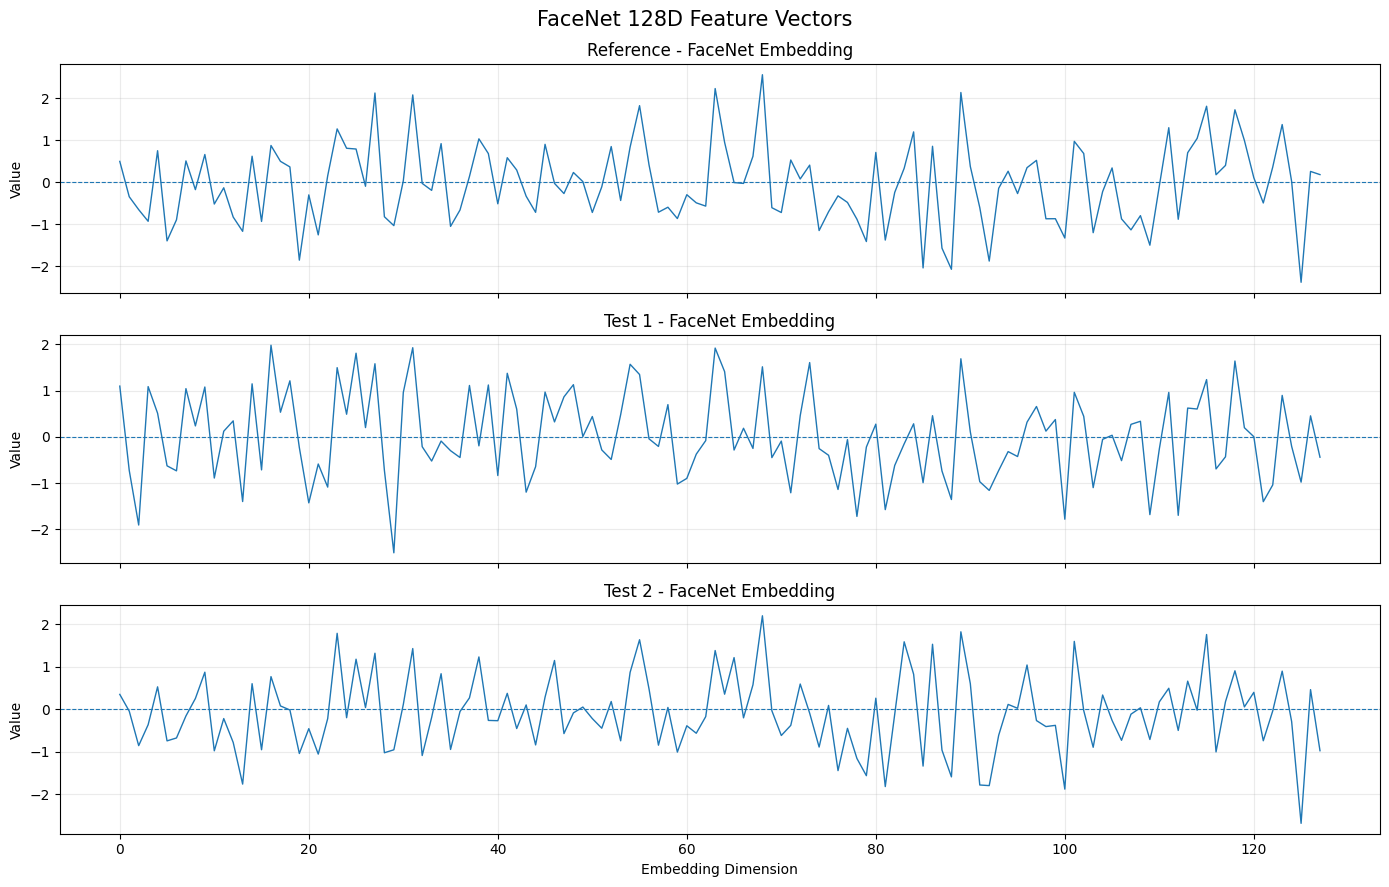

In [46]:
fig, axes = plt.subplots(
    len(embeddings), 1,
    figsize=(14, 9),
    sharex=True,
    squeeze=False
)

for ax, (name, embedding) in zip(axes.flat, embeddings.items()):
    ax.plot(np.arange(128), embedding, linewidth=1)
    ax.axhline(0, linestyle="--", linewidth=0.8)
    ax.set_title(f"{name} - FaceNet Embedding")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.25)

axes[-1, 0].set_xlabel("Embedding Dimension")
plt.suptitle("FaceNet 128D Feature Vectors", fontsize=15)
plt.tight_layout()
plt.show()

**Nhận xét embedding:**

Cả 3 vector có kích thước `(128,)`, giá trị hữu hạn. Chuẩn L2 quan sát được khoảng 10.14–10.85 (vector chưa chuẩn hóa), không ảnh hưởng đến cosine vì cosine chỉ xét hướng. Từng chiều riêng lẻ không có ý nghĩa trực quan; cần so sánh hai vector bằng độ đo cosine (Mục 3.4).

### 3.4. So khớp bằng độ tương đồng cosine

#### Phương pháp

Cosine đo góc giữa hai vector đặc trưng. Vector tham chiếu được so với vector của Test 1 và Test 2.

- similarity ≥ 0.70 → `Matched`
- similarity < 0.70 → `Unknown`

Ngưỡng 0.7 do đề bài quy định, chưa được tối ưu bằng dữ liệu kiểm định.

#### Kết quả

In [47]:
reference_embedding = embeddings["Reference"]

similarity_results = {}

for name, test_embedding in embeddings.items():

    if name == "Reference":
        continue

    similarity = float(
        np.dot(reference_embedding, test_embedding)
        / (
            np.linalg.norm(reference_embedding)
            * np.linalg.norm(test_embedding)
        )
    )

    label = (
        "Matched"
        if similarity >= SIMILARITY_THRESHOLD
        else "Unknown"
    )

    similarity_results[name] = {
        "similarity": similarity,
        "label": label
    }

    print(f"{name}: {similarity:.4f} → {label}")

Test 1: 0.7027 → Matched
Test 2: 0.8307 → Matched


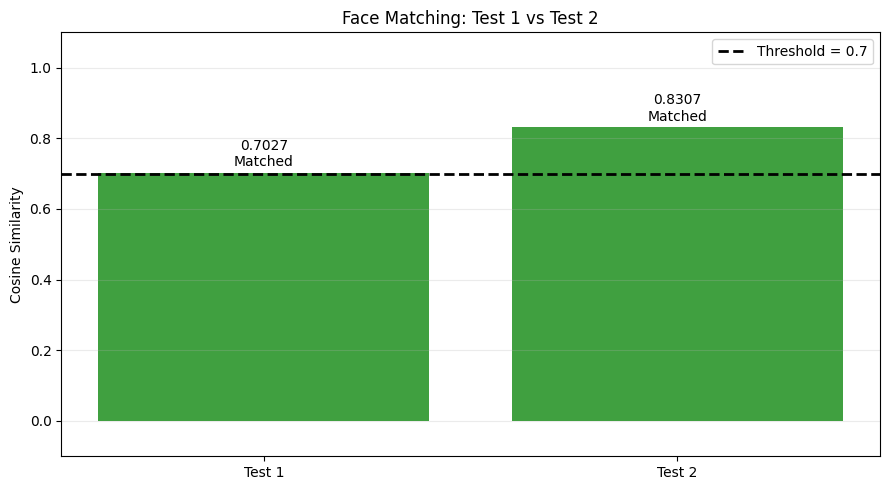

In [48]:
names = list(similarity_results.keys())

scores = [
    similarity_results[name]["similarity"]
    for name in names
]

labels = [
    similarity_results[name]["label"]
    for name in names
]

colors = [
    "green" if label == "Matched" else "red"
    for label in labels
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(names, scores, color=colors, alpha=0.75)

ax.axhline(
    SIMILARITY_THRESHOLD,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {SIMILARITY_THRESHOLD}"
)

for bar, score, label in zip(bars, scores, labels):
    ax.annotate(
        f"{score:.4f}\n{label}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_ylabel("Cosine Similarity")
ax.set_title("Face Matching: Test 1 vs Test 2")
ax.set_ylim(min(-0.1, min(scores) - 0.15), 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

#### Nhận xét kết quả so khớp

| Ảnh | Cosine | Dự đoán |
|---|---:|---|
| Test 1 | 0.7027 | Matched |
| Test 2 | 0.8307 | Matched |

Cả hai ảnh có cosine ≥ 0.70 nên được **dự đoán** `Matched`. Test 1 chỉ cao hơn ngưỡng 0.0027 nên kết quả có thể nhạy với điều kiện ảnh và thay đổi xử lý. **Không khẳng định dự đoán đúng** khi chưa xác nhận danh tính thực tế (`ground_truth`).

## 4. Thí nghiệm đối chứng Face Alignment (A/B/C)

### 4.1. Thiết kế thí nghiệm

Sử dụng **cùng ba ảnh, kết quả MTCNN, FaceNet, ngưỡng cosine 0.70** và xử lý ảnh tham chiếu theo **đúng cấu hình** của từng nhánh:

| Nhánh | Xoay theo mắt | Crop | Mục đích |
|---|---|---|---|
| **A – Raw MTCNN** | Không | Hộp MTCNN hình chữ nhật, resize bởi `FaceEmbedder` | Mốc so sánh pipeline thô |
| **B – Square + margin** | Không (góc = 0°) | Vuông, cạnh `ceil(max(w,h) × 1.25)`, phản xạ biên, resize 160 × 160 | Tách ảnh hưởng crop và lề |
| **C – Full alignment** | Có | Cùng quy tắc crop vuông/lề/resize của nhánh B | Xem tác động bổ sung của xoay theo mắt |

**Quan trọng:** Nhánh B mô phỏng đúng phép crop của `src.face_alignment.align_face()` nhưng cố định ma trận xoay là đồng nhất. Nhánh C vẫn gọi hàm gốc của project, không sửa code production. Vì phép xoay còn làm thay đổi nội suy pixel và vị trí tâm hộp, chênh lệch **B → C** đo tác động của *bước xoay trong pipeline này*, không nhất thiết quy được toàn bộ cho hướng mắt trên mọi ảnh.

- **A → B:** thay đổi cách lấy vùng mặt, không thay đổi góc ảnh.
- **B → C:** bổ sung phép xoay (cùng công thức tính cạnh crop, padding và resize).
- **A → C:** tác động tổng hợp của pipeline alignment.

### 4.2. Tạo ba phiên bản crop và kiểm tra trực quan


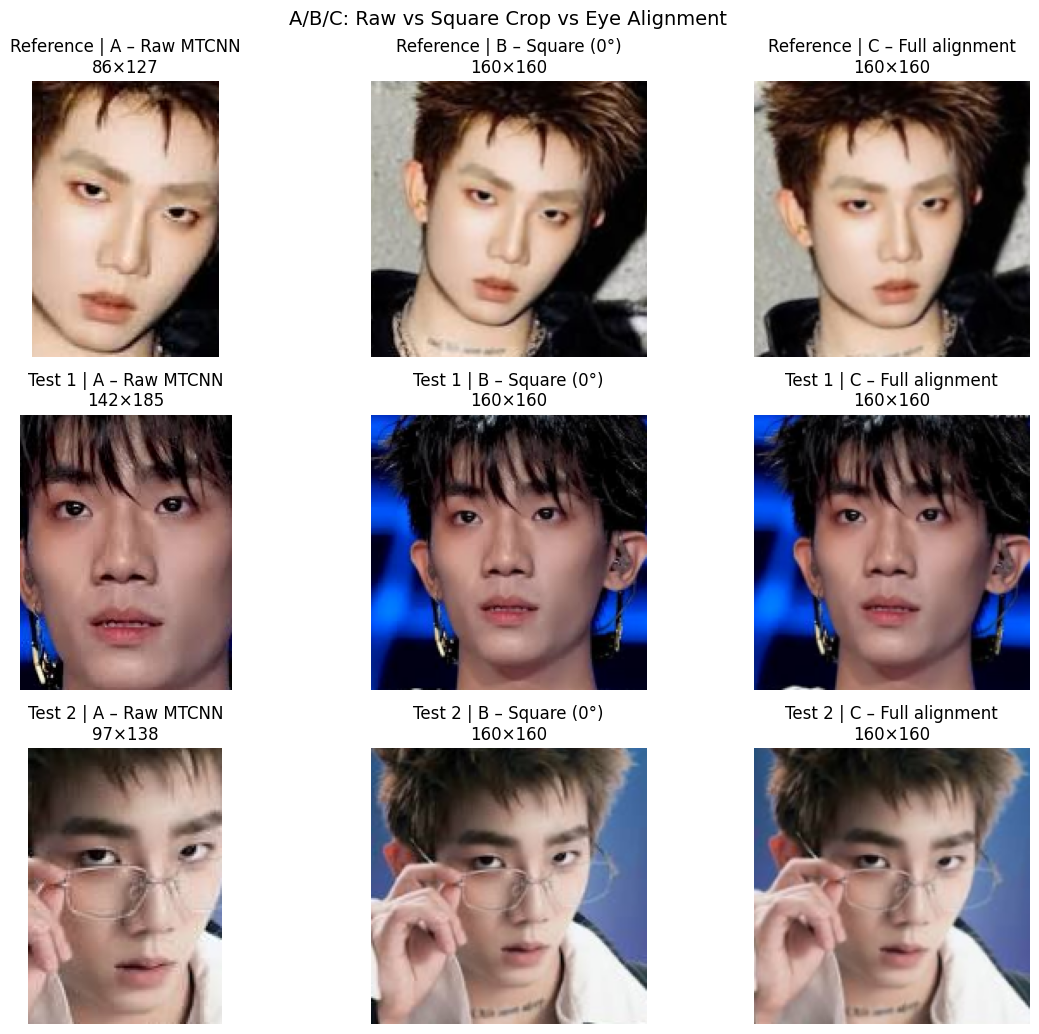

In [49]:
# Hàm nghiên cứu cho nhánh B: cùng crop/padding/resize với align_face,
# nhưng KHÔNG xoay ảnh, để tách biến số phép xoay.
# Không sửa src/face_alignment.py: chương trình chính vẫn dùng pipeline gốc.
def square_crop_without_rotation(image, face):
    if image is None or image.ndim != 3 or image.shape[2] != 3 or image.size == 0:
        raise ValueError("Invalid input image")
    x, y, w, h = face["box"]
    if w <= 0 or h <= 0:
        raise ValueError("Invalid face bounding box")
    side = max(1, int(np.ceil(max(w, h) * 1.25)))
    cx, cy = x + w / 2, y + h / 2  # angle=0 -> tâm không đổi
    pad = side
    padded = cv2.copyMakeBorder(
        image, pad, pad, pad, pad, cv2.BORDER_REFLECT_101
    )
    x1 = int(round(cx - side / 2)) + pad
    y1 = int(round(cy - side / 2)) + pad
    crop = padded[y1:y1 + side, x1:x1 + side]
    if crop.shape[:2] != (side, side):
        raise ValueError("Square crop is invalid")
    return cv2.resize(crop, (160, 160), interpolation=cv2.INTER_LINEAR)

# A: raw crop đã trích ở mục 3.2
# B: crop vuông + 25% lề, không xoay
# C: crop đã alignment theo mắt của module gốc
ablation_crops = {}
for name in aligned_faces:
    face = max(detection_results[name], key=lambda f: f["confidence"])
    ablation_crops[name] = {
        "A – Raw MTCNN": original_faces[name],
        "B – Square (0°)": square_crop_without_rotation(images[name], face),
        "C – Full alignment": aligned_faces[name],
    }

fig, axes = plt.subplots(len(ablation_crops), 3,
                         figsize=(12, 3.5 * len(ablation_crops)), squeeze=False)
for row_index, (name, crops) in enumerate(ablation_crops.items()):
    for col_index, (variant, crop) in enumerate(crops.items()):
        axes[row_index, col_index].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[row_index, col_index].set_title(f"{name} | {variant}\n{crop.shape[1]}×{crop.shape[0]}")
        axes[row_index, col_index].axis("off")
plt.suptitle("A/B/C: Raw vs Square Crop vs Eye Alignment", fontsize=14)
plt.tight_layout()
plt.show()


In [50]:
# Trích xuất FaceNet cho cùng một tập ảnh, mỗi nhánh xử lý cả Reference và Test.
# Tái sử dụng embedding C đã tính ở Mục 3.3 (không chạy lại khác cấu hình).
variant_embeddings = {"A – Raw MTCNN": {}, "B – Square (0°)": {},
                      "C – Full alignment": embeddings.copy()}
for name, crops in ablation_crops.items():
    for variant in ("A – Raw MTCNN", "B – Square (0°)"):
        emb = embedder.extract(crops[variant])
        assert emb.shape == (128,) and np.all(np.isfinite(emb)), (name, variant)
        variant_embeddings[variant][name] = emb

# Tính cosine trên cặp embedding được xử lý NHẤT QUÁN theo từng nhánh.
def cosine_of(a, b):
    denominator = float(np.linalg.norm(a) * np.linalg.norm(b))
    if denominator <= 0:
        raise ValueError("Zero-norm FaceNet embedding")
    return float(np.dot(a, b) / denominator)

ablation_results = {}
for name in similarity_results:
    scores = {}
    for variant, per_image in variant_embeddings.items():
        scores[variant] = cosine_of(per_image["Reference"], per_image[name])
    ablation_results[name] = {
        **scores,
        "B - A (crop effect)": scores["B – Square (0°)"] - scores["A – Raw MTCNN"],
        "C - B (rotation step)": scores["C – Full alignment"] - scores["B – Square (0°)"],
        "C - A (total)": scores["C – Full alignment"] - scores["A – Raw MTCNN"],
    }

ablation_df = pd.DataFrame.from_dict(ablation_results, orient="index") if "pd" in globals() else None
if ablation_df is None:
    import pandas as pd
    ablation_df = pd.DataFrame.from_dict(ablation_results, orient="index")
ablation_df.index.name = "Test Image"
from IPython.display import display as show_table
show_table(ablation_df.round(4))

# Nhánh C được tính từ embedding đã trình bày ở Mục 3.4.
for name in ablation_results:
    assert np.isclose(
        ablation_results[name]["C – Full alignment"],
        similarity_results[name]["similarity"], atol=1e-5
    ), f"Aligned result mismatch for {name}"


,A – Raw MTCNN,B – Square (0°),C – Full alignment,B - A (crop effect),C - B (rotation step),C - A (total)
Test Image,,,,,,
Test 1,0.6036,0.5928,0.7027,-0.0108,0.1099,0.0991
Test 2,0.8038,0.7939,0.8307,-0.0098,0.0368,0.0269


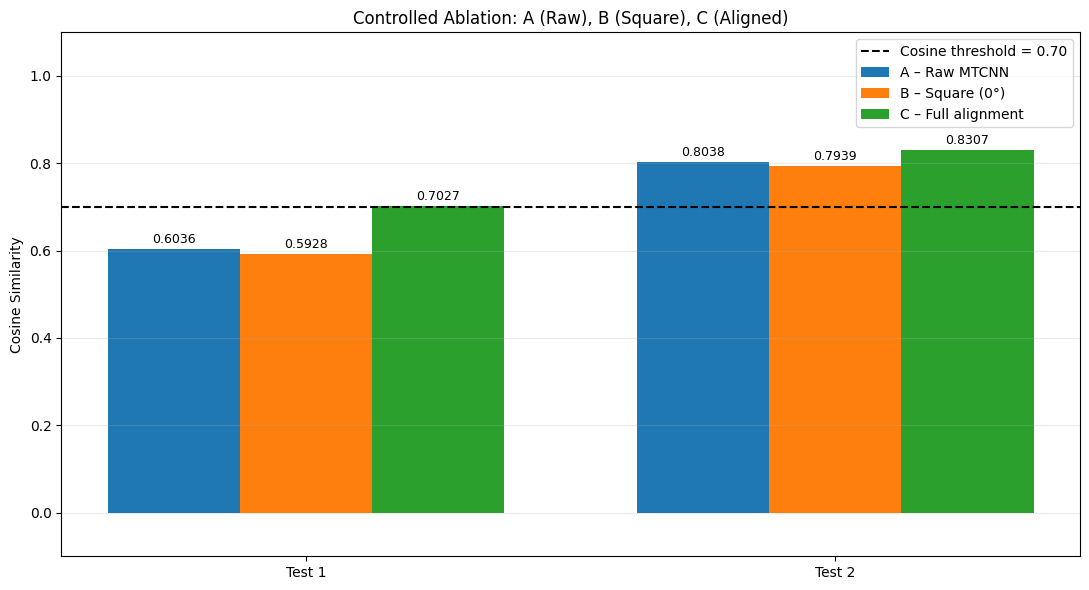

In [51]:
variants = ["A – Raw MTCNN", "B – Square (0°)", "C – Full alignment"]
names = list(ablation_results)
x = np.arange(len(names))
bar_width = 0.25
fig, ax = plt.subplots(figsize=(11, 6))
for j, variant in enumerate(variants):
    values = [ablation_results[name][variant] for name in names]
    bars = ax.bar(x + (j - 1) * bar_width, values, bar_width, label=variant)
    ax.bar_label(bars, fmt="%.4f", padding=2, fontsize=9)
ax.axhline(SIMILARITY_THRESHOLD, color="black", linestyle="--",
           label=f"Cosine threshold = {SIMILARITY_THRESHOLD:.2f}")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Cosine Similarity")
ax.set_title("Controlled Ablation: A (Raw), B (Square), C (Aligned)")
ax.set_ylim(min(-0.1, float(ablation_df[variants].min().min()) - .12), 1.1)
ax.legend()
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


### 4.3. Diễn giải kết quả sau khi chạy

Bảng và biểu đồ ở trên **được tính trực tiếp khi chạy notebook**; không gán sẵn con số cho nhánh B.

- **B − A:** ảnh hưởng của cách crop (hình chữ nhật → hình vuông có lề 25%) khi giữ nguyên góc ảnh.
- **C − B:** chênh lệch khi thêm bước xoay theo mắt, với cùng công thức crop, lề và kích thước đầu ra.
- **C − A:** tổng chênh lệch của pipeline alignment so với crop MTCNN thô.

Cần lưu ý: **cosine similarity tăng không đồng nghĩa accuracy tăng**, nhất là khi thí nghiệm chỉ có một ảnh tham chiếu và hai ảnh thử, chưa có ground truth đã xác nhận. Đối với ảnh gần thẳng, B và C có thể rất giống nhau; không mặc định C tốt hơn B. Với ngưỡng 0.70, có thể báo cáo sự thay đổi *dự đoán* giữa các nhánh, nhưng không gọi đó là tăng độ chính xác nếu chưa có nhãn danh tính thực tế.


## 5. Tổng hợp và giới hạn của thí nghiệm ba ảnh

### 5.1. Bảng tổng hợp

`Prediction` là kết quả dự đoán theo ngưỡng 0.70. `Expected`/`Correct` chỉ có ý nghĩa khi xác nhận được danh tính thực tế của Test 1 và Test 2. Nếu chưa xác minh, giữ `None` và **không tính độ chính xác** cho thí nghiệm này.

In [52]:
import pandas as pd
from IPython.display import display as show_table

# Điền nhãn thực tế nếu xác minh được danh tính:
# "Matched" = cùng người với Reference; "Unknown" = người khác.
ground_truth = {"Test 1": None, "Test 2": None}

summary_rows = []
for name, result in similarity_results.items():
    faces = detection_results.get(name, [])
    expected = ground_truth.get(name)
    prediction = result["label"]
    summary_rows.append({
        "Test Image": name,
        "Detection Confidence": max((f["confidence"] for f in faces), default=None),
        "Similarity A (Raw)": ablation_results[name]["A – Raw MTCNN"],
        "Similarity B (Square)": ablation_results[name]["B – Square (0°)"],
        "Similarity C (Aligned)": ablation_results[name]["C – Full alignment"],
        "B - A": ablation_results[name]["B - A (crop effect)"],
        "C - B": ablation_results[name]["C - B (rotation step)"],
        "Prediction (C)": prediction,
        "Expected": expected,
        "Correct (C)": prediction == expected if expected is not None else None,
    })
summary_df = pd.DataFrame(summary_rows)
show_table(summary_df.round(4))


,Test Image,Detection Confidence,Similarity A (Raw),Similarity B (Square),Similarity C (Aligned),B - A,C - B,Prediction (C),Expected,Correct (C)
0,Test 1,0.9998,0.6036,0.5928,0.7027,-0.0108,0.1099,Matched,None,None
1,Test 2,0.9999,0.8038,0.7939,0.8307,-0.0098,0.0368,Matched,None,None


### 5.2. Hạn chế

- Thí nghiệm chỉ có 1 ảnh tham chiếu và 2 ảnh thử; `ground_truth` chưa được xác nhận, nên **không tính accuracy** cho ba ảnh này.
- Test 1 đạt cosine khoảng **0.7027** ở nhánh C, sát ngưỡng 0.70. Giá trị được tính lại trong mục 3.4 khi chạy.
- A/B/C giữ cố định mô hình FaceNet và dùng **mỗi nhánh cho cả ảnh Reference lẫn ảnh Test**; nhánh B tách thay đổi crop khỏi bước xoay ở nhánh C.
- So sánh B → C vẫn bao gồm sai khác do nội suy và thay đổi vị trí crop sau xoay; không chứng minh quan hệ nhân quả phổ quát từ 2 ảnh thử.
- Chưa đánh giá định lượng đầy đủ ảnh hưởng ánh sáng, góc nhìn, che khuất và khoảng cách.

### 5.3. Kết luận thí nghiệm minh họa

MTCNN, FaceNet và cosine matching hoạt động trên ba ảnh minh họa. Kết quả A/B/C trình bày ở Mục 4 phân biệt tác động của **cách crop**, **bước xoay** và **toàn bộ pipeline**. Không kết luận rằng alignment luôn tăng similarity hoặc accuracy; đánh giá 100 cặp ở Mục 6 thuộc một thí nghiệm khác và không phải phép kiểm chứng độc lập cho kết luận về xoay ảnh.

### 5.4. Hướng mở rộng

Thực hiện thí nghiệm A/B/C trên nhiều cặp Same/Different có góc nghiêng được ghi nhận; kiểm tra occlusion bằng tỷ lệ phát hiện và tỷ lệ xác minh đúng theo mức che mặt. Mục 6 đánh giá face verification tổng thể; Mục 7 đọc benchmark webcam.


## 6. Đánh giá Face Verification trên 100 cặp ảnh (Georgia Tech)

Sử dụng `data/pair_evaluation/pairs.csv` đã chuẩn bị trước, gồm `image1`, `image2`, `label` (1 = Same, 0 = Different). Notebook 01 kiểm tra dữ liệu và file cặp ảnh, **không tự tạo lại file**.

- 100 cặp gồm 50 Same và 50 Different; 91 ảnh duy nhất, có ảnh lặp giữa các cặp.
- Ảnh nằm trong `data/gt_db/`, đường dẫn CSV tính từ thư mục gốc.
- Pipeline: MTCNN → Alignment → FaceNet → cosine → Same/Different.
- Ngưỡng cố định 0.70, không tối ưu trên chính tập đánh giá.
- Đây là **pair verification**, khác với việc webcam so khớp với một ảnh tham chiếu và khác với đánh giá độ chính xác của tracking.

**Lưu ý:** Mục 6.5 phân tích độ nhạy sau khi tạo `outputs/evaluation/pair_results.csv`. Không chọn ngưỡng tối ưu từ chính tập đánh giá.


In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
from IPython.display import display as show_table
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc
)

# Sử dụng ROOT đã xác định tại Mục 2.1, không ghi đè bằng Path.cwd().
print("Project root:", ROOT)


# ============================================================
# 2. KHAI BÁO ĐƯỜNG DẪN
# ============================================================

PAIRS_CSV = ROOT / "data" / "pair_evaluation" / "pairs.csv"
OUTPUT_DIR = ROOT / "outputs" / "evaluation"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Pairs CSV:", PAIRS_CSV)
print("CSV exists:", PAIRS_CSV.is_file())

if not PAIRS_CSV.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy {PAIRS_CSV}. "
        "Hãy kiểm tra Cell 5 của notebook 01."
    )


# ============================================================
# 3. ĐỌC DỮ LIỆU PAIRS
# ============================================================

pairs = pd.read_csv(
    PAIRS_CSV,
    dtype={
        "image1": str,
        "image2": str,
        "label": int
    }
)

required = {"image1", "image2", "label"}

assert required.issubset(pairs.columns), (
    f"Thiếu cột: {required - set(pairs.columns)}"
)

assert len(pairs) == 100, (
    f"Dự kiến 100 cặp, hiện có {len(pairs)}"
)

assert set(pairs["label"]) == {0, 1}, (
    "Nhãn phải là 0 hoặc 1"
)

assert (pairs["image1"] != pairs["image2"]).all(), (
    "Có cặp ảnh trùng chính nó"
)

assert (
    (pairs["label"] == 1).sum() == 50
    and (pairs["label"] == 0).sum() == 50
), "Số lượng Positive/Negative không đúng"


# ============================================================
# 4. KIỂM TRA ĐƯỜNG DẪN ẢNH
# ============================================================

# Hỗ trợ đường dẫn Windows có dấu \
def resolve_image(relative_path):
    normalized = str(relative_path).replace("\\", "/")
    return ROOT.joinpath(*normalized.split("/"))


unique_files = sorted(
    set(pairs["image1"]) | set(pairs["image2"])
)

missing_files = [
    name
    for name in unique_files
    if not resolve_image(name).is_file()
]

assert not missing_files, (
    f"Thiếu {len(missing_files)} ảnh, "
    f"ví dụ: {missing_files[:3]}"
)


# ============================================================
# 5. KIỂM TRA NHÃN POSITIVE / NEGATIVE
# ============================================================

person1 = pairs["image1"].map(
    lambda p: Path(
        str(p).replace("\\", "/")
    ).parent.name
)

person2 = pairs["image2"].map(
    lambda p: Path(
        str(p).replace("\\", "/")
    ).parent.name
)

assert (
    (person1 == person2).astype(int) == pairs["label"]
).all(), "Nhãn không khớp danh tính"


# ============================================================
# 6. CHUẨN HÓA TÊN CỘT CHO NOTEBOOK 02
# ============================================================

pairs = pairs.rename(
    columns={
        "image1": "image_a",
        "image2": "image_b"
    }
)

pairs["label"] = pairs["label"].map({
    1: "Same",
    0: "Different"
})


# ============================================================
# 7. HIỂN THỊ KẾT QUẢ
# ============================================================

show_table(pairs.head(10))

print("\n========== DATASET SUMMARY ==========")
print("Total pairs:", len(pairs))
print("Positive (Same):", (pairs["label"] == "Same").sum())
print("Negative (Different):", (pairs["label"] == "Different").sum())
print("Unique images:", len(unique_files))
print("Missing images:", len(missing_files))
print("Dataset validation: PASSED")

Project root: C:\Users\NAO\Downloads\lab5_face_ID
Pairs CSV: C:\Users\NAO\Downloads\lab5_face_ID\data\pair_evaluation\pairs.csv
CSV exists: True


,image_a,image_b,label
0,data\gt_db\s18\01.jpg,data\gt_db\s18\10.jpg,Same
1,data\gt_db\s15\01.jpg,data\gt_db\s15\13.jpg,Same
2,data\gt_db\s02\14.jpg,data\gt_db\s09\15.jpg,Different
3,data\gt_db\s18\04.jpg,data\gt_db\s41\01.jpg,Different
4,data\gt_db\s02\15.jpg,data\gt_db\s02\05.jpg,Same
5,data\gt_db\s08\08.jpg,data\gt_db\s41\01.jpg,Different
6,data\gt_db\s09\14.jpg,data\gt_db\s09\05.jpg,Same
7,data\gt_db\s09\11.jpg,data\gt_db\s09\13.jpg,Same
8,data\gt_db\s07\10.jpg,data\gt_db\s07\04.jpg,Same
9,data\gt_db\s08\04.jpg,data\gt_db\s16\06.jpg,Different



========== DATASET SUMMARY ==========
Total pairs: 100
Positive (Same): 50
Negative (Different): 50
Unique images: 91
Missing images: 0
Dataset validation: PASSED


### 6.1. Trích xuất đặc trưng (cache mỗi ảnh một lần)
Áp dụng đúng pipeline của project. Nếu không có đúng một khuôn mặt hợp lệ, ghi nhận lỗi và tính cặp đó là dự đoán sai trong Accuracy tổng thể, thay vì bỏ âm thầm khỏi tập test.

In [54]:
from src.face_detector import FaceDetector
from src.face_alignment import align_face
from src.face_embedder import FaceEmbedder
from src.config import MIN_CONFIDENCE, MIN_FACE_SIZE, SIMILARITY_THRESHOLD

detector_pair = FaceDetector()
embedder_pair = FaceEmbedder()
embedding_cache = {}
error_cache = {}

for filename in unique_files:
    try:
        image = cv2.imread(str(resolve_image(filename)))
        if image is None:
            raise ValueError("Cannot read image")
        faces = detector_pair.detect(image)
        valid = [face for face in faces
                 if face["confidence"] >= MIN_CONFIDENCE
                 and face["box"][2] >= MIN_FACE_SIZE
                 and face["box"][3] >= MIN_FACE_SIZE]
        if len(valid) != 1:
            raise ValueError(f"Expected 1 valid face; found {len(valid)}")
        vector = np.asarray(embedder_pair.extract(align_face(image, valid[0])), dtype=np.float32)
        if vector.shape != (128,) or not np.isfinite(vector).all():
            raise ValueError("Invalid FaceNet embedding")
        embedding_cache[filename] = vector
    except (ValueError, cv2.error) as exc:
        error_cache[filename] = str(exc)

print(f"Valid embeddings: {len(embedding_cache)}/{len(unique_files)}")
if error_cache:
    show_table(pd.DataFrame([{"file": k, "error": v} for k, v in error_cache.items()]))

Valid embeddings: 91/91


In [55]:
from src.face_matcher import FaceMatcher

matcher_pair = FaceMatcher(threshold=SIMILARITY_THRESHOLD)
records = []
for row in pairs.itertuples(index=False):
    a, b = row.image_a, row.image_b
    record = {"image_a": a, "image_b": b, "label": row.label,
              "similarity": np.nan,
              "prediction": "Processing Failed", "status": "failed"}
    if a in embedding_cache and b in embedding_cache:
        match = matcher_pair.match(embedding_cache[a], embedding_cache[b])
        record.update(similarity=match["similarity"],
                      prediction="Same" if match["label"] == "Matched" else "Different",
                      status="ok")
    record["correct"] = record["prediction"] == record["label"]
    records.append(record)

pair_results = pd.DataFrame(records)
pair_results.to_csv(OUTPUT_DIR / "pair_results.csv", index=False, encoding="utf-8-sig")
show_table(pair_results.head(10))
print(f"Overall accuracy (including failures): {pair_results.correct.mean():.2%}")
print(f"Failed pairs: {(pair_results.status != 'ok').sum()}")
print("Saved:", OUTPUT_DIR / "pair_results.csv")

,image_a,image_b,label,similarity,prediction,status,correct
0,data\gt_db\s18\01.jpg,data\gt_db\s18\10.jpg,Same,0.733843,Same,ok,True
1,data\gt_db\s15\01.jpg,data\gt_db\s15\13.jpg,Same,0.913971,Same,ok,True
2,data\gt_db\s02\14.jpg,data\gt_db\s09\15.jpg,Different,0.294398,Different,ok,True
3,data\gt_db\s18\04.jpg,data\gt_db\s41\01.jpg,Different,0.140326,Different,ok,True
4,data\gt_db\s02\15.jpg,data\gt_db\s02\05.jpg,Same,0.872863,Same,ok,True
5,data\gt_db\s08\08.jpg,data\gt_db\s41\01.jpg,Different,0.290482,Different,ok,True
6,data\gt_db\s09\14.jpg,data\gt_db\s09\05.jpg,Same,0.818627,Same,ok,True
7,data\gt_db\s09\11.jpg,data\gt_db\s09\13.jpg,Same,0.863766,Same,ok,True
8,data\gt_db\s07\10.jpg,data\gt_db\s07\04.jpg,Same,0.756841,Same,ok,True
9,data\gt_db\s08\04.jpg,data\gt_db\s16\06.jpg,Different,0.127174,Different,ok,True


Overall accuracy (including failures): 100.00%
Failed pairs: 0
Saved: C:\Users\NAO\Downloads\lab5_face_ID\outputs\evaluation\pair_results.csv


### 6.2. Confusion Matrix, Precision, Recall, F1 và ROC
- Báo cáo Accuracy toàn bộ cặp, kể cả cặp xử lý lỗi.
- Confusion matrix 2 lớp chỉ tính các cặp có embedding hợp lệ và ghi rõ số cặp bị loại khỏi ma trận.
- ROC/AUC chỉ tính trên các cặp có similarity hợp lệ và cả hai lớp. Không thể tính ROC nếu chỉ có Same hoặc chỉ có Different.
- TPR (Sensitivity) = tỷ lệ cặp Same được nhận đúng; TNR (Specificity) = tỷ lệ cặp Different được nhận đúng.

Valid pairs for 2-class metrics: 100/100
              precision    recall  f1-score   support

   Different       1.00      1.00      1.00        50
        Same       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



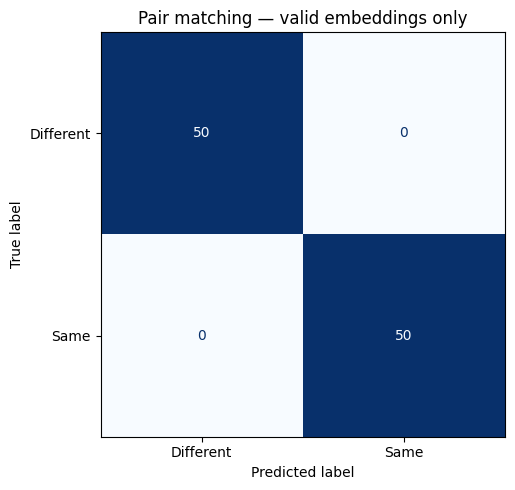

Sensitivity (Same recall): 1.000
Specificity (Different recall): 1.000


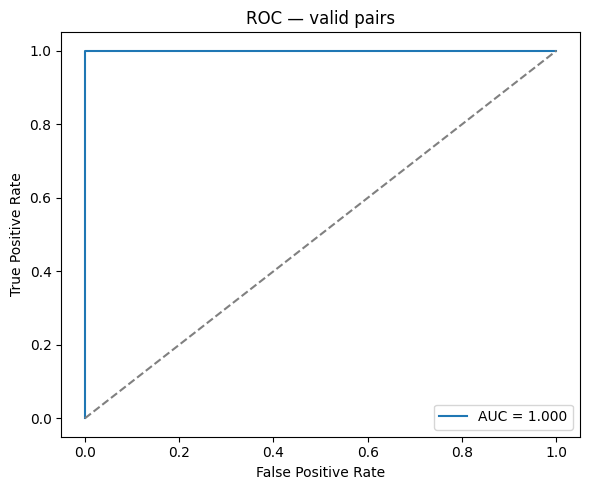

In [56]:
valid_results = pair_results[pair_results["status"] == "ok"].copy()
print(f"Valid pairs for 2-class metrics: {len(valid_results)}/{len(pair_results)}")
if len(valid_results):
    labels = ["Different", "Same"]
    print(classification_report(valid_results["label"], valid_results["prediction"],
                                labels=labels, zero_division=0))
    cm = confusion_matrix(valid_results["label"], valid_results["prediction"], labels=labels)
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title("Pair matching — valid embeddings only")
    plt.tight_layout()
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print("Sensitivity (Same recall):", f"{tp / (tp + fn):.3f}" if tp + fn else "N/A")
    print("Specificity (Different recall):", f"{tn / (tn + fp):.3f}" if tn + fp else "N/A")
else:
    print("Không có cặp hợp lệ để tính confusion matrix")

if valid_results["label"].nunique() == 2:
    y_true = (valid_results["label"] == "Same").astype(int)
    fpr, tpr, thresholds = roc_curve(y_true, valid_results["similarity"])
    roc_auc = auc(fpr, tpr)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC — valid pairs")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("ROC/AUC không khả dụng: cần cả cặp Same và Different hợp lệ")


### 6.3. Phân bố Cosine Similarity

So sánh phân bố độ tương đồng của các cặp Same và Different trên các cặp xử lý thành công. Dataset chưa có nhãn góc mặt/điều kiện ánh sáng theo từng ảnh, nên không kết luận độ chính xác theo điều kiện.

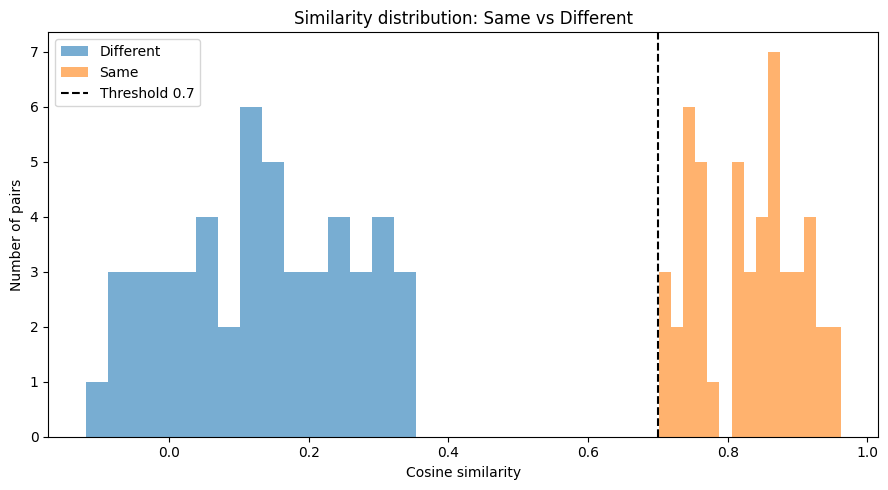

,label,pairs,accuracy,mean_similarity
0,Different,50,1.0,0.133071
1,Same,50,1.0,0.829508


In [57]:
if len(valid_results):
    fig, ax = plt.subplots(figsize=(9, 5))
    for label, group in valid_results.groupby("label"):
        ax.hist(group["similarity"], bins=15, alpha=0.6, label=label)
    ax.axvline(SIMILARITY_THRESHOLD, linestyle="--", color="black", label="Threshold 0.7")
    ax.set(xlabel="Cosine similarity", ylabel="Number of pairs", title="Similarity distribution: Same vs Different")
    ax.legend()
    plt.tight_layout()
    plt.show()
    show_table(valid_results.groupby("label").agg(
        pairs=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_similarity=("similarity", "mean")
    ).reset_index())
else:
    print("Không có cặp hợp lệ để vẽ phân bố similarity")

### 6.4. Minh họa các cặp ảnh đúng và sai

Chọn tối đa 3 cặp đúng và 3 cặp sai. Đây là minh họa kết quả thực tế sau khi chạy, không dùng số liệu giả định.

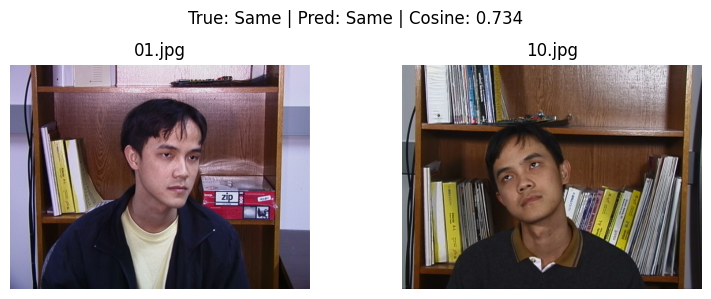

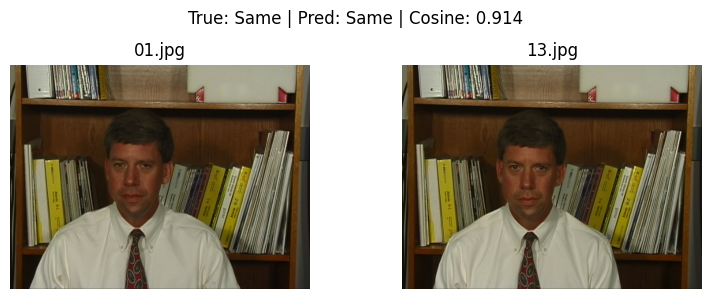

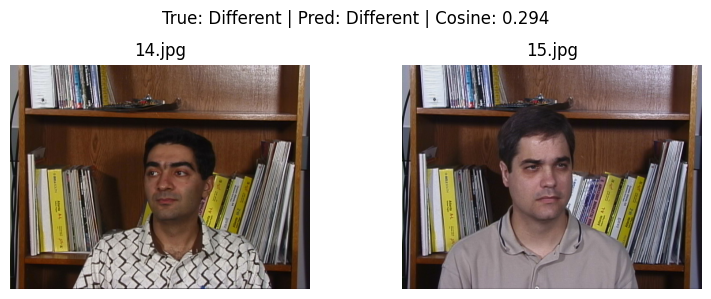

In [58]:
examples = pd.concat([
    pair_results[pair_results.correct].head(3),
    pair_results[~pair_results.correct].head(3)
]).head(6)
for row in examples.itertuples(index=False):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    for ax, filename in zip(axes, [row.image_a, row.image_b]):
        image = cv2.imread(str(resolve_image(filename)))
        if image is not None:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(Path(str(filename).replace("\\", "/")).name)
        ax.axis("off")
    sim = "N/A" if pd.isna(row.similarity) else f"{row.similarity:.3f}"
    fig.suptitle(f"True: {row.label} | Pred: {row.prediction} | Cosine: {sim}")
    plt.tight_layout()
    plt.show()

### 6.5. Phân tích độ nhạy của ngưỡng Cosine Similarity

Mục tiêu: Khảo sát ảnh hưởng của ngưỡng cosine similarity đến
Accuracy, Precision, Recall, F1-score, FAR và FRR.

Dữ liệu sử dụng: 100 cặp ảnh Same/Different đã được đánh giá.

**Diễn giải:** Độ chính xác 100% chỉ đúng với 100 cặp được chọn, không chứng minh độ chính xác ngoài thực tế. Trên tập này, similarity thấp nhất của Same khoảng **0.7014** và cao nhất của Different khoảng **0.3541**; ngưỡng **0.70** chỉ cách biên Same khoảng **0.0014**. Khoảng **0.40–0.70** cho 31 ngưỡng không lỗi trong phép quét bước 0.01, nhưng không nên chọn ngưỡng mới chỉ dựa trên tập đánh giá. Đặc biệt Test 1 trong thí nghiệm ba ảnh đạt **0.7027** sau căn chỉnh và **0.6036** khi bỏ căn chỉnh. Cần tập validation độc lập với điều kiện khó hơn (kính, nghiêng, ánh sáng) để kiểm tra độ bền.

In [59]:

csv_path = ROOT / "outputs" / "evaluation" / "pair_results.csv"

df_threshold = pd.read_csv(csv_path)

print("Shape:", df_threshold.shape)
print("Columns:", df_threshold.columns.tolist())
print("\nMissing values:")
print(df_threshold.isna().sum())

show_table(df_threshold.head(10))


Shape: (100, 7)
Columns: ['image_a', 'image_b', 'label', 'similarity', 'prediction', 'status', 'correct']

Missing values:
image_a       0
image_b       0
label         0
similarity    0
prediction    0
status        0
correct       0
dtype: int64


,image_a,image_b,label,similarity,prediction,status,correct
0,data\gt_db\s18\01.jpg,data\gt_db\s18\10.jpg,Same,0.733843,Same,ok,True
1,data\gt_db\s15\01.jpg,data\gt_db\s15\13.jpg,Same,0.913971,Same,ok,True
2,data\gt_db\s02\14.jpg,data\gt_db\s09\15.jpg,Different,0.294398,Different,ok,True
3,data\gt_db\s18\04.jpg,data\gt_db\s41\01.jpg,Different,0.140326,Different,ok,True
4,data\gt_db\s02\15.jpg,data\gt_db\s02\05.jpg,Same,0.872863,Same,ok,True
5,data\gt_db\s08\08.jpg,data\gt_db\s41\01.jpg,Different,0.290482,Different,ok,True
6,data\gt_db\s09\14.jpg,data\gt_db\s09\05.jpg,Same,0.818627,Same,ok,True
7,data\gt_db\s09\11.jpg,data\gt_db\s09\13.jpg,Same,0.863766,Same,ok,True
8,data\gt_db\s07\10.jpg,data\gt_db\s07\04.jpg,Same,0.756841,Same,ok,True
9,data\gt_db\s08\04.jpg,data\gt_db\s16\06.jpg,Different,0.127174,Different,ok,True


In [60]:

print("Ground-truth labels:")
print(df_threshold["label"].value_counts(dropna=False))

print("\nPrediction values:")
print(df_threshold["prediction"].value_counts(dropna=False))

print("\nProcessing status:")
print(df_threshold["status"].value_counts(dropna=False))

print("\nSimilarity statistics by label:")
show_table(
    df_threshold.groupby("label")["similarity"]
    .agg(["count", "min", "max", "mean", "std"])
)


Ground-truth labels:
label
Same         50
Different    50
Name: count, dtype: int64

Prediction values:
prediction
Same         50
Different    50
Name: count, dtype: int64

Processing status:
status
ok    100
Name: count, dtype: int64

Similarity statistics by label:


,count,min,max,mean,std
label,,,,,
Different,50,-0.119437,0.354115,0.133071,0.127830
Same,50,0.701426,0.961881,0.829508,0.071801


In [61]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Same = 1 (positive), Different = 0 (negative)
y_true = df_threshold["label"].map({
    "Same": 1,
    "Different": 0
}).to_numpy()

similarities = df_threshold["similarity"].to_numpy()

assert not np.isnan(y_true.astype(float)).any(), "Invalid labels"
assert np.isfinite(similarities).all(), "Invalid similarities"

# Khảo sát từ 0.40 đến 0.80, bước 0.01
thresholds = np.round(np.arange(0.40, 0.801, 0.01), 2)

results = []

for threshold in thresholds:
    y_pred = (similarities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    far = fp / (fp + tn) if (fp + tn) else np.nan
    frr = fn / (fn + tp) if (fn + tp) else np.nan

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "FAR": far,
        "FRR": frr,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(results)

show_table(threshold_df.round(4))


,Threshold,Accuracy,Precision,Recall,F1,FAR,FRR,TP,TN,FP,FN
0,0.40,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
1,0.41,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
2,0.42,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
3,0.43,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
4,0.44,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
5,0.45,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
6,0.46,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
7,0.47,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
8,0.48,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0
9,0.49,1.00,1.0,1.00,1.0000,0.0,0.00,50,50,0,0


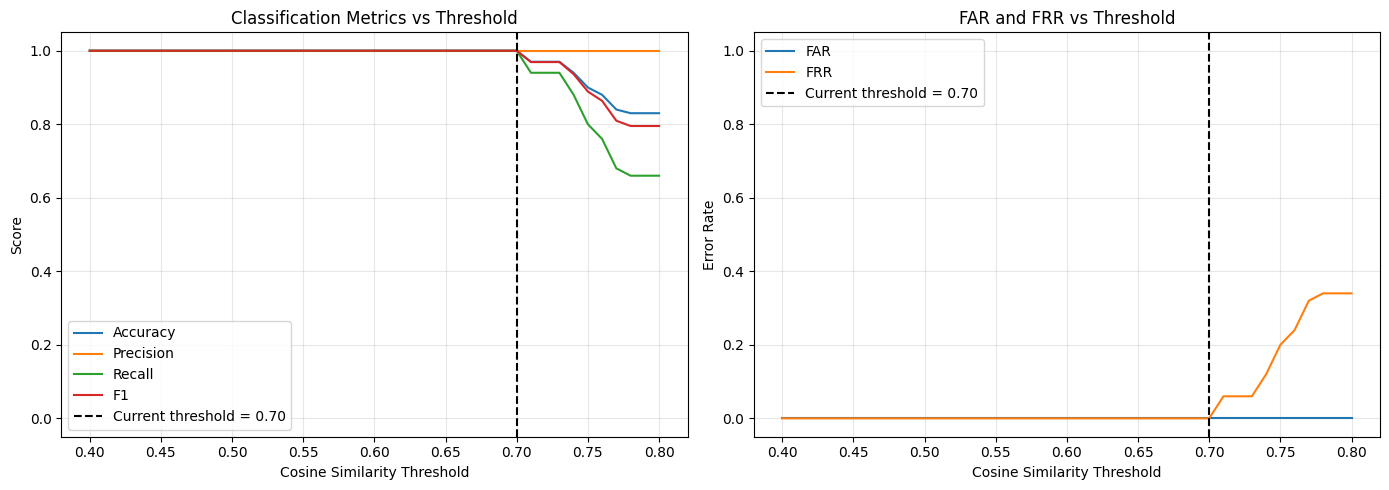

In [62]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy, Precision, Recall, F1
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    axes[0].plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        label=metric
    )

axes[0].axvline(0.70, linestyle="--", color="black",
                label="Current threshold = 0.70")
axes[0].set_title("Classification Metrics vs Threshold")
axes[0].set_xlabel("Cosine Similarity Threshold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend()
axes[0].grid(alpha=0.3)

# FAR, FRR
axes[1].plot(
    threshold_df["Threshold"],
    threshold_df["FAR"],
    label="FAR"
)
axes[1].plot(
    threshold_df["Threshold"],
    threshold_df["FRR"],
    label="FRR"
)

axes[1].axvline(0.70, linestyle="--", color="black",
                label="Current threshold = 0.70")
axes[1].set_title("FAR and FRR vs Threshold")
axes[1].set_xlabel("Cosine Similarity Threshold")
axes[1].set_ylabel("Error Rate")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [63]:

# Các ngưỡng không tạo lỗi trên tập dữ liệu hiện tại
zero_error = threshold_df[
    (threshold_df["FAR"] == 0) &
    (threshold_df["FRR"] == 0)
]

print("Number of zero-error thresholds:", len(zero_error))

if not zero_error.empty:
    print(
        "Zero-error threshold range:",
        zero_error["Threshold"].min(),
        "to",
        zero_error["Threshold"].max()
    )

print("\nCurrent threshold = 0.70:")
show_table(threshold_df[np.isclose(threshold_df["Threshold"], 0.70)])


Number of zero-error thresholds: 31
Zero-error threshold range: 0.4 to 0.7

Current threshold = 0.70:


,Threshold,Accuracy,Precision,Recall,F1,FAR,FRR,TP,TN,FP,FN
30,0.7,1.0,1.0,1.0,1.0,0.0,0.0,50,50,0,0


## 7. Đánh giá hiệu năng webcam

Chạy `python benchmark_webcam.py` từ thư mục gốc trước để tạo CSV trong `outputs/benchmark/`. Notebook chỉ **đọc kết quả**, không tự mở webcam. Trục X là **thứ tự mẫu**, không phải thời gian (giây), vì CSV chứa `sample` và `latency_ms`. FPS đo vòng lặp hiển thị, không phải thông lượng FaceNet.

In [64]:
BENCHMARK_DIR = ROOT / "outputs" / "benchmark"
tracking_csv = BENCHMARK_DIR / "tracking_latency.csv"
recognition_csv = BENCHMARK_DIR / "recognition_latency.csv"
summary_csv = BENCHMARK_DIR / "summary.csv"

for path in (tracking_csv, recognition_csv, summary_csv):
    if not path.exists():
        raise FileNotFoundError(f"Chưa có {path}. Chạy benchmark_webcam.py trước.")

tracking_df = pd.read_csv(tracking_csv)
recognition_df = pd.read_csv(recognition_csv)
summary_df = pd.read_csv(summary_csv)
show_table(summary_df)

,metric,value
0,duration_s,60.018654
1,frames,1794.000000
2,avg_fps,29.890707
3,tracking_count,1778.000000
4,tracking_mean_ms,1.558866
5,tracking_median_ms,1.454400
6,tracking_min_ms,1.196500
7,tracking_max_ms,5.613100
8,recognition_count,30.000000
9,recognition_mean_ms,401.220373


In [65]:
print("Tracking columns:", tracking_df.columns.tolist())
print("Recognition columns:", recognition_df.columns.tolist())

show_table(tracking_df.head())
show_table(recognition_df.head())

Tracking columns: ['sample', 'latency_ms']
Recognition columns: ['sample', 'latency_ms']


,sample,latency_ms
0,1,1.9934
1,2,1.5834
2,3,1.5834
3,4,1.6628
4,5,1.8890


,sample,latency_ms
0,1,490.6035
1,2,408.2265
2,3,384.5530
3,4,389.0434
4,5,417.6005


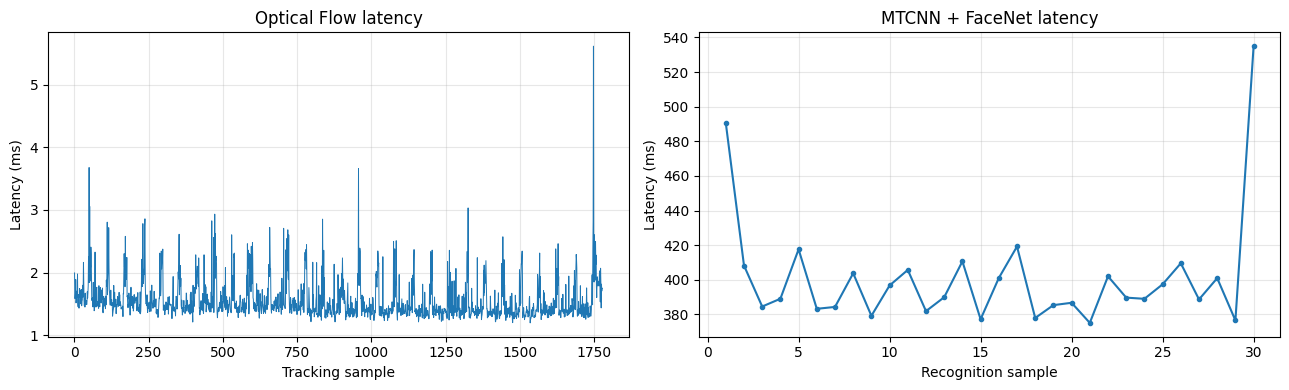

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Tracking latency
axes[0].plot(
    range(1, len(tracking_df) + 1),
    tracking_df["latency_ms"],
    linewidth=0.7
)
axes[0].set(
    title="Optical Flow latency",
    xlabel="Tracking sample",
    ylabel="Latency (ms)"
)

# Recognition latency
axes[1].plot(
    range(1, len(recognition_df) + 1),
    recognition_df["latency_ms"],
    marker="o",
    markersize=3
)
axes[1].set(
    title="MTCNN + FaceNet latency",
    xlabel="Recognition sample",
    ylabel="Latency (ms)"
)

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Kết luận và giới hạn thực nghiệm

Thực nghiệm **pair verification** trên Georgia Tech gồm **100 cặp** (50 Same, 50 Different), sử dụng **91 ảnh duy nhất**. Cả 91 ảnh đều được trích xuất embedding thành công, không có cặp xử lý lỗi. Với ngưỡng cosine 0.70, hệ thống phân loại đúng **100/100 cặp**: Accuracy 100%, Precision/Recall/F1 cho lớp Same đều 1.00, Sensitivity và Specificity đều 1.00. Không ghi nhận False Positive hoặc False Negative trên mẫu đã chọn. Đây không phải độ chính xác tổng quát ngoài thực tế vì tập nhỏ, các cặp có thể dùng chung ảnh và chưa kiểm định trên danh tính/điều kiện độc lập.

Benchmark webcam ghi nhận **60.01 giây**, **1793 frame**, **29.88 FPS của vòng lặp hiển thị**. Optical Flow có latency trung bình **2.11 ms** (1.767 mẫu), trong khi nhận diện MTCNN + FaceNet trung bình **776.23 ms** (30 mẫu). Việc chạy nhận diện trên luồng nền và tracking ở các frame trung gian giúp duy trì tốc độ hiển thị gần 30 FPS trong lần thử này; không nên hiểu FPS này là số lần FaceNet suy luận mỗi giây.

**Giới hạn:** chưa có ground truth để chấm đúng/sai cho thí nghiệm ba ảnh; chưa đánh giá định lượng độ chính xác tracking; chưa đánh giá đa danh tính, chống giả mạo, thay đổi điều kiện ánh sáng/góc mặt có hệ thống hoặc hiệu chỉnh ngưỡng trên tập validation độc lập. Kết quả phù hợp để minh họa một hệ thống so khớp với **một ảnh tham chiếu**, không đủ cơ sở cho ứng dụng xác thực bảo mật.

**Lưu ý về ngưỡng:** Việc đạt 100% trên 100 cặp Georgia Tech không đồng nghĩa hệ thống nhận diện đúng 100% trong thực tế. Mặc dù các cặp Different có similarity tối đa khoảng 0.3541, cặp Same thấp nhất chỉ đạt khoảng 0.7014, sát ngưỡng 0.70. Ở thí nghiệm ba ảnh, Test 1 từng có similarity 0.7027 ở pipeline alignment; Mục 4 hiện dùng đối chứng A/B/C để tách ảnh hưởng của crop và bước xoay. Các giá trị A/B/C phải đọc từ kết quả chạy lại, không suy diễn từ chênh lệch cũ. Dữ liệu hiện tại chưa đủ để kết luận 0.70 là ngưỡng tối ưu; cần validation độc lập với góc nhìn, kính, ánh sáng và che khuất đa dạng.

**Ghi chú Face Alignment A/B/C:** So sánh nhánh B và C giúp cô lập thay đổi do bước xoay trong cùng quy tắc crop, nhưng chỉ với hai ảnh kiểm thử thì chưa đủ để khẳng định phép xoay cải thiện face verification nói chung.
